# Mapping de reads sur le génome de *P. falciparum*

Le programme cherche les positions de reads courts dans la référence avec des k-mers, la BWT et DC3. Après il vérifie  les régions candidates en acceptant des substitutions et de petits indels (score d'alignement etc..).

In [1]:
from pathlib import Path
import sys

DOSSIER = Path.cwd()
print("Dossier de travail :", DOSSIER)
necessaires = ("requirements.txt", "GenomToolBox.py", "Workflow.py", "evaluation.py")
manquants = [nom for nom in necessaires if not (DOSSIER / nom).is_file()]
if manquants:
    raise FileNotFoundError(
        "Fichiers manquants : " + ", ".join(manquants)
        + ". Ouvrir le dossier contenant le notebook et ces fichiers, puis relancer le noyau depuis ce dossier.")
if str(DOSSIER) not in sys.path:
    sys.path.insert(0, str(DOSSIER))

Dossier de travail : C:\Users\yassb\Desktop\PROJET GENOMIQUE\genomique4bi


### Installer les dépendances dans le Python du notebook

Exécuter cette cellule à la première utilisation

In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


### Importer les bibliothèques et repérer les données

In [3]:
from time import perf_counter
from importlib.metadata import version
import json
import matplotlib.pyplot as plt

from GenomToolBox import BWT
from Workflow import (lire_reference, lire_fastq, echantillonner_fastq,
                      construire_index, mapper_reads, mapper_flux, nettoyer_read)
from evaluation import evaluer_fichier, evaluer_mapping, ajuster_verite_nettoyage

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})
DONNEES = DOSSIER
if not (DONNEES / "GCF_000002765.5_GCA_000002765_genomic.fna.gz").is_file():
    DONNEES = DOSSIER / "donnees"
FASTA = DONNEES / "GCF_000002765.5_GCA_000002765_genomic.fna.gz"
FASTQ = DONNEES / "single_Pfal_dat.fq.gz"
BAM = DONNEES / "single_Pfal_dat.bam"
for fichier in (FASTA, FASTQ, BAM):
    if not fichier.is_file():
        raise FileNotFoundError("Fichier manquant : " + str(fichier))
print("Python", sys.version.split()[0])
print({nom: version(nom) for nom in ("numpy", "biopython", "bamnostic", "matplotlib")})

Python 3.12.10
{'numpy': '2.4.6', 'biopython': '1.88', 'bamnostic': '1.3', 'matplotlib': '3.10.9'}


## Paramètres à choisir

| Paramètre | Rôle |
|---|---|
| NOMBRE_READS | 0 : tout le FASTQ ; valeur positive : échantillon aléatoire de cette taille |
| GRAINE | Permet de retrouver le même échantillon et les mêmes reads pour les petits essais |
| K | Longueur des k-mers ; plus grand : plus spécifique, mais plus sensible aux erreurs |
| ERREURS | Nombre maximal de substitutions + insertions + délétions acceptées |
| MAX_OCCURRENCES | Ignore les k-mers trop répétés et borne les placements exacts très nombreux |
| MAX_CANDIDATS | Nombre de débuts candidats examinés avant les décalages liés aux indels |

Augmenter ou diminuer k ou d change le compromis entre sensibilité et temps de calcul

In [4]:
# Paramètres de l'expérience
NOMBRE_READS = 1000              # 0 = c'est pour lire tous les reads (attention cela prend beaucoup de temps))
GRAINE = 42
K = 21
ERREURS = 3
MAX_OCCURRENCES = 200
MAX_CANDIDATS = 30

if NOMBRE_READS < 0:
    raise ValueError("Le nombre de reads doit être positif ou nul.")
if K <= 0 or ERREURS < 0 or MAX_OCCURRENCES <= 0 or MAX_CANDIDATS <= 0:
    raise ValueError("Paramètres de mapping invalides.")
parametres = {"k": K, "erreurs": ERREURS,
              "max_occurrences": MAX_OCCURRENCES, "max_candidats": MAX_CANDIDATS}
mode = "complet" if NOMBRE_READS == 0 else "echantillon_" + str(NOMBRE_READS)
SORTIES = DOSSIER / ("sorties_" + mode)
SORTIES.mkdir(exist_ok=True)
CSV = SORTIES / "placements.csv"
JSONL = SORTIES / "placements.jsonl"
BILAN = SORTIES / "bilan.json"

# Paramètres enregistrés avec les résultats.
configuration = {"nombre_reads": NOMBRE_READS, "graine": GRAINE,
                 "parametres": parametres,
                 "fichiers": {p.name: [p.stat().st_size, p.stat().st_mtime_ns]
                              for p in (FASTA, FASTQ, BAM)}}
print("Mode :", mode)
print("Résultats dans :", SORTIES)

Mode : echantillon_1000
Résultats dans : C:\Users\yassb\Desktop\PROJET GENOMIQUE\genomique4bi\sorties_echantillon_1000


## 1. Préparer la référence

Biopython lit le FASTA. On construit un index par chromosome, sans permettre de chevauchement sur deux séquences. DC3 trie les suffixes ; la BWT et ses compteurs servent aux recherches exactes.

Les index sont conservés dans `index_bwt`.

In [5]:
debut = perf_counter()
references = lire_reference(FASTA)
temps_fasta = perf_counter() - debut
print("Séquences de référence :", len(references))
print("Longueur totale :", sum(map(len, references.values())), "bases")
print("Lecture du FASTA :", round(temps_fasta, 2), "s")

debut = perf_counter()
indexes = construire_index(references, dossier_cache=DOSSIER / "index_bwt")
temps_index = perf_counter() - debut
print("Préparation des index :", round(temps_index, 2), "s")

Séquences de référence : 15
Longueur totale : 23326872 bases
Lecture du FASTA : 0.53 s


NC_004325.2 : 640,851 bases, index chargé en 0.27 s


NC_037280.1 : 947,102 bases, index chargé en 0.42 s


NC_000521.4 : 1,067,971 bases, index chargé en 0.46 s


NC_004318.2 : 1,200,490 bases, index chargé en 0.55 s


...

NC_037284.1 : 2,271,494 bases, index chargé en 1.05 s


NC_004331.3 : 2,925,236 bases, index chargé en 1.34 s


NC_037283.1 : 3,291,936 bases, index chargé en 1.48 s


NC_036769.1 : 34,250 bases, index chargé en 0.02 s


Préparation des index : 10.82 s


## 2. Mapper les reads


### Algorithme de mapping

La fonction `mapper_read` est dans `Workflow.py`. Elle suit ces étapes :

1. Chercher le read entier sur les deux brins. Si des placements exacts existent, les conserver.
2. Sinon, chercher ses k-mers. Chaque occurrence propose un début : position dans la référence moins position dans le read.
3. Ignorer les k-mers trop répétés, puis garder les débuts recevant le plus de votes.
4. Tester les régions candidates, avec de petits décalages pour les insertions et délétions.
5. Aligner le read entier et conserver les placements de distance minimale, dans la limite d'erreurs choisie.
6. Signaler les réponses multiples comme ambiguës. Sans placement acceptable, le read est non mappé.

### Calcul complet et mémoire

En mode complet, `lire_fastq` fournit un read à la fois. `mapper_flux` écrit son résultat dans le CSV et le JSONL, puis passe au suivant. Le JSONL contient un résultat complet par ligne ; le CSV contient une ligne par placement.

Les statuts et les qualités sont comptés sur tous les reads. Pour la qualité, un petit histogramme par position remplace une matrice contenant toutes les lectures. On conserve au plus 30 reads et leurs résultats pour les illustrations et les petits essais.

Le dossier de sorties doit avoir de la place pour les résultats et la base temporaire d'évaluation. Plusieurs Go peuvent être nécessaires selon le nombre de placements répétés. Chaque exécution de la cellule de mapping recommence le calcul et remplace les sorties du mode choisi.

In [6]:
sauvegarde = {"configuration": configuration, "termine": False}
BILAN.write_text(json.dumps(sauvegarde), encoding="utf-8")

debut = perf_counter()
if NOMBRE_READS == 0:
    lectures = lire_fastq(FASTQ)
else:
    lectures, total_fastq = echantillonner_fastq(FASTQ, NOMBRE_READS, GRAINE)
    print("Échantillon :", len(lectures), "parmi", total_fastq, "reads")
temps_selection = perf_counter() - debut

# On garde seulement 30 exemples pour les figures et les petits essais.
resume = mapper_flux(lectures, indexes, CSV, JSONL, apercu=30, graine=GRAINE,
                     afficher_tous=1000, **parametres)
resume["temps_selection"] = temps_selection
sauvegarde["calcul"] = resume
BILAN.write_text(json.dumps(sauvegarde, ensure_ascii=False, indent=2), encoding="utf-8")

if resume["total"] == 0:
    raise ValueError("Aucun read dans le fichier choisi.")
reads = resume["reads_apercu"]
resultats_apercu = resume["resultats_apercu"]
temps_mapping = resume["temps_secondes"]
print("Reads traités :", resume["total"])
print("Statuts :", resume["statuts"])
print("Recherches limitées :", resume["recherches_limitees"])
print("Reads conservés pour les petits essais :", len(reads))
print("Lecture, mapping et écriture :", round(temps_mapping, 2), "s")

Échantillon : 1000 parmi 1500000 reads


1,000 reads traités en 16.8 s


Terminé : 1,000 reads, 16.81 s


Reads traités : 1000
Statuts : {'mappe': 912, 'ambigu': 79, 'non_mappe': 9}
Recherches limitées : 179
Reads conservés pour les petits essais : 30
Lecture, mapping et écriture : 16.81 s


### Limites de la recherche

Les k-mers trop fréquent et le nombre de candidats sont bornés pour limiter le temps. `recherche_limitee` indique qu'un plafond a été atteint. Un read non mappé peut avoir été manqué par la recherche 

Un grand k risque de ne laisser aucun k-mer exact après les erreurs. Avec L=100, k=21 et d=3, la condition L >= k(d+1) garantit au moins une graine intacte avant les plafonds.

Les lettres IUPAC sont comparées littéralement. Les grands réarrangements et les reads appariés ne sont pas pris en charge.

## 3. Qualité de tous les reads traités

Le graphique utilise les histogrammes accumulés pendant le mapping, donc tous les reads du calcul choisi. Il montre la qualité Phred moyenne à chaque position. Une baisse en fin de read peut justifier d'examiner un nettoyage, sans suffire à en décider.

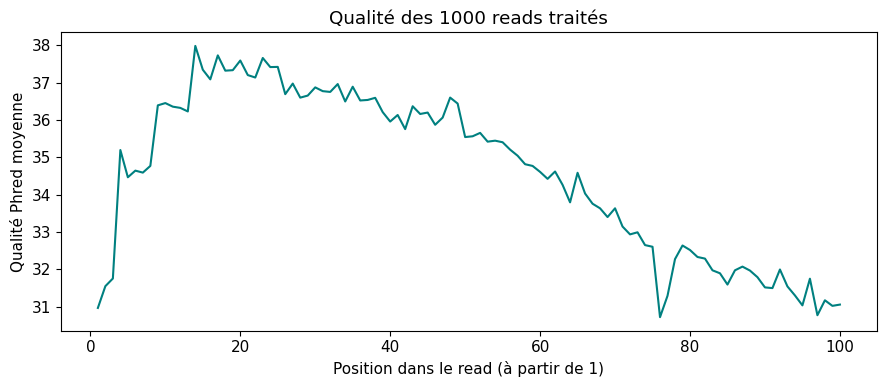

In [7]:
moyennes = []
for histogramme in resume["qualites"]:
    total = sum(histogramme.values())
    moyennes.append(sum(int(q) * n for q, n in histogramme.items()) / total)
positions = range(1, len(moyennes) + 1)
fig, ax = plt.subplots()
ax.plot(positions, moyennes, color="teal")
ax.set(xlabel="Position dans le read (à partir de 1)", ylabel="Qualité Phred moyenne",
       title="Qualité des " + str(resume["total"]) + " reads traités")
fig.tight_layout()
plt.show()

### Questions posées à l'index et support d'un read conservé

`compter` fournit le nombre d'occurrences exactes d'un motif dans une référence. `rechercher_adn` fournit les positions sur les deux brins. Pour un palindrome, `+/-` représente les deux orientations au même endroit.

Le support d'un motif au sens du sujet est son nombre d'occurrences. Le champ `support` d'un placement compte, lui, les offsets de k-mers qui soutiennent sa région.

Présence et support direct du premier k-mer : 1
Mot à la position 0 : TGAACCCTAAAACCTAAACCC
Premières positions sur les deux brins : []


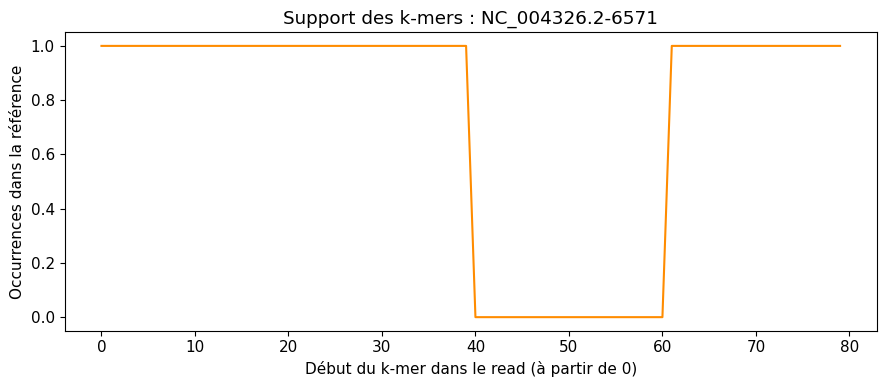

Placements proposés : [{'position': 795608, 'fin': 795708, 'distance': 1, 'substitutions': 1, 'insertions': 0, 'deletions': 0, 'chromosome': 'NC_004326.2', 'brin': '+', 'support': 59}]


In [8]:
indice = next((i for i, r in enumerate(resultats_apercu)
               if r["alignements"] and r["alignements"][0]["distance"] > 0), 0)
read = reads[indice]
motif = read["sequence"][:K]
print("Présence et support direct du premier k-mer :",
      sum(index.compter(motif) for index in indexes.values()))
premier_chromosome = next(iter(indexes))
print("Mot à la position 0 :", indexes[premier_chromosome].mot_a_position(0, K))
print("Premières positions sur les deux brins :",
      indexes[premier_chromosome].rechercher_adn(motif)[:5])
supports = []
for i in range(len(read["sequence"]) - K + 1):
    motif = read["sequence"][i:i + K]
    inverse = BWT.complementaire_inverse(motif)
    support = sum(index.compter(motif) for index in indexes.values())
    if motif != inverse:
        support += sum(index.compter(inverse) for index in indexes.values())
    supports.append(support)
fig, ax = plt.subplots()
ax.plot(range(len(supports)), supports, color="darkorange")
ax.set(xlabel="Début du k-mer dans le read (à partir de 0)",
       ylabel="Occurrences dans la référence", title="Support des k-mers : " + read["id"])
fig.tight_layout()
plt.show()
print("Placements proposés :", resultats_apercu[indice]["alignements"][:2])

## 4. Comparer tous les résultats au BAM

Le BAM sert uniquement à l'évaluation. On compare par identifiant, sans supposer le même ordre entre FASTQ et BAM. Pour ne pas conserver toutes les réponses en mémoire, SQLite les indexe temporairement sur disque. Le BAM est parcouru une seule fois.

Le critère strict exige le même chromosome, la même position gauche et un brin compatible. La fin et le détail des opérations d'alignement ne sont pas comparés.

In [9]:
debut = perf_counter()
bilan, _ = evaluer_fichier(
    JSONL, BAM, dossier_travail=SORTIES, tolerance=0,
    identifiants_apercu=[r["id"] for r in reads])
temps_bam = perf_counter() - debut
sauvegarde["evaluation"] = {"strict": bilan, "temps_secondes": temps_bam}
BILAN.write_text(json.dumps(sauvegarde, ensure_ascii=False, indent=2), encoding="utf-8")

if bilan["total"] != resume["total"]:
    raise ValueError("Le nombre de résultats évalués ne correspond pas au mapping.")
verite_apercu = bilan["verite_apercu"]
print("Reads traités et évalués :", bilan["total"])
print("Reads avec une vérité mappée :", bilan["evaluables"])
print("Origine retrouvée :", bilan["origine_retrouvee"])
print("Taux d'origine retrouvée :", bilan["taux_origine_retrouvee"])
print("Réponses uniques correctes :", bilan["uniques_corrects"], "/", bilan["uniques_evaluables"])
print("Précision des réponses uniques :", bilan["precision_uniques"])
print("Ambigus :", bilan["ambigus"], "; non mappés :", bilan["non_mappes"])
print("Sans vérité :", bilan["sans_verite"], "; recherches limitées :", bilan["recherches_limitees"])
print("Préparation sur disque et lecture du BAM :", round(temps_bam, 2), "s")

Évaluation : 100,000 enregistrements BAM parcourus


Évaluation : 200,000 enregistrements BAM parcourus


Évaluation : 300,000 enregistrements BAM parcourus


Évaluation : 400,000 enregistrements BAM parcourus


Évaluation : 500,000 enregistrements BAM parcourus


...

Évaluation : 1,200,000 enregistrements BAM parcourus


Évaluation : 1,300,000 enregistrements BAM parcourus


Évaluation : 1,400,000 enregistrements BAM parcourus


Évaluation : 1,500,000 enregistrements BAM parcourus


Reads traités et évalués : 1000
Reads avec une vérité mappée : 1000
Origine retrouvée : 991
Taux d'origine retrouvée : 0.991
Réponses uniques correctes : 912 / 912
Précision des réponses uniques : 1.0
Ambigus : 79 ; non mappés : 9
Sans vérité : 0 ; recherches limitées : 179
Préparation sur disque et lecture du BAM : 137.74 s


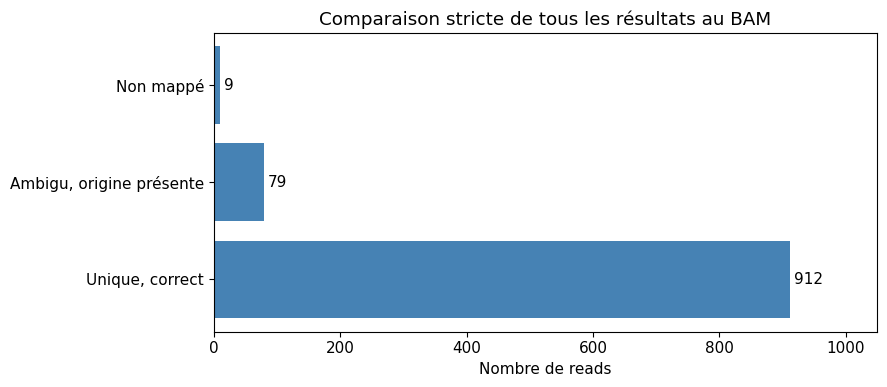

In [10]:
categories = bilan["categories"]
fig, ax = plt.subplots()
barres = ax.barh(list(categories), list(categories.values()), color="steelblue")
ax.bar_label(barres, padding=3)
ax.set(xlabel="Nombre de reads", title="Comparaison stricte de tous les résultats au BAM")
ax.set_xlim(0, max(categories.values()) * 1.15 + 1)
fig.tight_layout()
plt.show()

### Interpréter les résultats

Le nombre de reads évalués doit correspondre au nombre de reads traités. En mode complet, il doit couvrir le FASTQ entier. 

Les plafonds de recherche peuvent masquer des placements. Un read non mappé peut dépasser le seuil d'erreurs

## 5. Petit essai sur la longueur k

On reprend les 30 reads conservés avec k=15, 21 et 27. Tous les autres paramètres restent identiques. On compare le temps de mapping et la proportion d'origines retrouvées, avec le même critère strict que dans l'analyse principale.

Un petit k produit plus de correspondances répétées ; un grand k risque de perdre les graines exactes en présence d'erreurs. Cet essai illustre le compromis, mais 30 reads ne suffisent pas à choisir un k optimal pour le fichier entier. Si le calcul porte sur moins de 30 reads, ils sont tous utilisés.


{'k': 15, 'secondes': 0.6318567999987863, 'origine_retrouvee': 1.0}


{'k': 21, 'secondes': 0.5405419000308029, 'origine_retrouvee': 1.0}


{'k': 27, 'secondes': 0.5109172000084072, 'origine_retrouvee': 1.0}


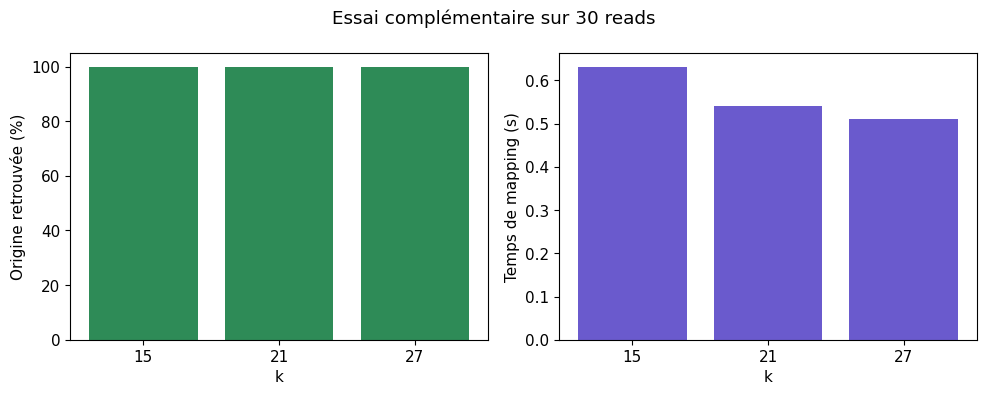

In [11]:
comparaison_k = []
petit_echantillon = reads[:30]
for k_test in (15, 21, 27):
    debut = perf_counter()
    reponses = mapper_reads(petit_echantillon, indexes, k=k_test, erreurs=ERREURS,
                             max_occurrences=MAX_OCCURRENCES, max_candidats=MAX_CANDIDATS)
    duree = perf_counter() - debut
    mesure = evaluer_mapping(reponses, verite_apercu)
    comparaison_k.append({"k": k_test, "secondes": duree,
                         "origine_retrouvee": mesure["taux_origine_retrouvee"]})
    print(comparaison_k[-1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = [str(r["k"]) for r in comparaison_k]
pourcentages = [100 * r["origine_retrouvee"] if r["origine_retrouvee"] is not None else float("nan")
                for r in comparaison_k]
axes[0].bar(labels, pourcentages, color="seagreen")
axes[0].set(xlabel="k", ylabel="Origine retrouvée (%)", ylim=(0, 105))
axes[1].bar(labels, [r["secondes"] for r in comparaison_k], color="slateblue")
axes[1].set(xlabel="k", ylabel="Temps de mapping (s)")
fig.suptitle("Essai complémentaire sur " + str(len(petit_echantillon)) + " reads")
fig.tight_layout()
plt.show()

## 6. Complexités et temps

On note n la longueur de référence, N le nombre de reads, L leur longueur, C le nombre de chromosomes, Q=L-k+1 et h le nombre d'occurrences d'un motif.

| Étape | Temps | Mémoire supplémentaire |
|---|---|---|
| DC3 puis BWT, alphabet fixé | O(n) théorique | O(n) |
| Compter un motif de longueur k | O(k x 128) ici | O(1) |
| Chercher et trier h positions | O(k x 128 + h log h) | O(h) |
| Chercher les k-mers d'un read | O(CQk x 128), plus les correspondances | Dépend des correspondances |
| Aligner un départ avec au plus d erreurs | O(L(d+1)) | O(L(d+1)) |
| Lire le FASTQ entier | O(NL) | Un read à la fois |
| Garder s exemples et les qualités | O(NL) au total | O(sL + Lq), q = nombre de scores Phred possibles |
| Indexer et joindre les résultats au BAM | Recherches SQLite en O(log N), plus lecture du BAM | Cache borné ; O(N + placements) sur disque |

128 est le pas fixe des compteurs. Si V origines reçoivent des votes, leur tri coûte O(V log V). Pour R origines retenues, on teste jusqu'à R(2d+1) départs ; les alignements coûtent donc au plus O(R(2d+1)L(d+1)) par read.

Pour accélérer les recherches BWT, on mémorise les intervalles correspondant aux suffixes ADN de six lettres : au plus 4096 entrées par chromosome. Les graines et les plafonds ne changent pas. L'alignement conserve seulement la bande où la distance peut rester sous la limite, et réduit cette limite lorsqu'une meilleure réponse a déjà été trouvée. Les réponses ex aequo sont conservées.


In [12]:
temps = {"Lecture FASTA": temps_fasta, "Index (construction ou cache)": temps_index,
         "Sélection éventuelle": resume["temps_selection"],
         "Lecture + mapping + écriture": temps_mapping, "Évaluation sur disque + BAM": temps_bam}
for etape, duree in temps.items():
    print(etape, ":", round(duree, 2), "s")

Lecture FASTA : 0.53 s
Index (construction ou cache) : 10.82 s
Sélection éventuelle : 13.39 s
Lecture + mapping + écriture : 16.81 s
Évaluation sur disque + BAM : 137.74 s


## 7. Petit essai de nettoyage

On compare les mêmes 30 reads avant et après un nettoyage simple : retirer les bases de qualité inférieure à 20 à l'extrémité 3', jusqu'à rencontrer une base de qualité suffisante. Il peut réduire les erreurs, mais raccourcit les reads et peut les rendre moins spécifiques.

Les paramètres de mapping sont identiques avant et après. Un read devenu plus court que k est compté  comme non mappé et reste dans le bilan : on ne l'enlève pas pour améliorer le taux de réussite.

La position attendue est ajustée à partir de l'alignement du BAM pour la  portion du read conservée. C'est nécessaire sur le brin inverse, où couper l'extrémité 3' peut déplacer le début sur la référence ; les insertions et délétions sont aussi prises en compte.

Le mapping principal utilise toujours les reads d'origine. Ce petit  essai indique si le nettoyage aide sur ces exemples ; il ne permet pas de conclure pour le fichier entier. Il est refait quand cette cellule est exécutée.

Avant : 30 reads
Raccourcis : 0 ; bases retirées : 0
Trop courts : 0 ; non mappés : 0
Après : 30 reads
Raccourcis : 4 ; bases retirées : 4
Trop courts : 0 ; non mappés : 0


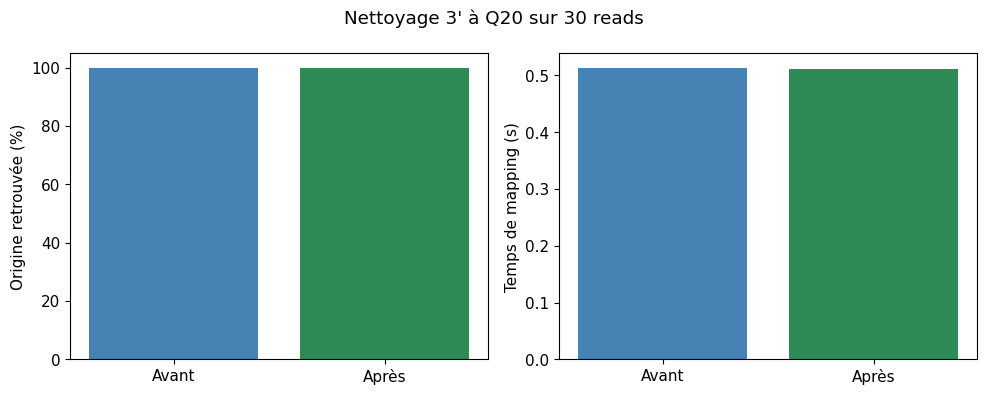

141197

In [13]:
SEUIL_QUALITE = 20
avant_nettoyage = reads[:30]
apres_nettoyage = [nettoyer_read(read, SEUIL_QUALITE) for read in avant_nettoyage]
verite_nettoyee = ajuster_verite_nettoyage(verite_apercu, avant_nettoyage, apres_nettoyage)

comparaison_nettoyage = []
for condition, lectures, attendu in (("Avant", avant_nettoyage, verite_apercu),
                                     ("Après", apres_nettoyage, verite_nettoyee)):
    debut = perf_counter()
    reponses = mapper_reads(lectures, indexes, **parametres)
    duree = perf_counter() - debut
    mesure = evaluer_mapping(reponses, attendu)
    comparaison_nettoyage.append({
        "condition": condition, "nombre_reads": len(lectures),
        "reads_raccourcis": sum(r.get("bases_retirees", 0) > 0 for r in lectures),
        "bases_retirees": sum(r.get("bases_retirees", 0) for r in lectures),
        "reads_trop_courts": sum(len(r["sequence"]) < K for r in lectures),
        "origine_retrouvee": mesure["taux_origine_retrouvee"],
        "precision_uniques": mesure["precision_uniques"],
        "non_mappes": mesure["non_mappes"], "ambigus": mesure["ambigus"],
        "secondes": duree})

for r in comparaison_nettoyage:
    print(r["condition"], ":", r["nombre_reads"], "reads")
    print("Raccourcis :", r["reads_raccourcis"], "; bases retirées :", r["bases_retirees"])
    print("Trop courts :", r["reads_trop_courts"], "; non mappés :", r["non_mappes"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = [r["condition"] for r in comparaison_nettoyage]
pourcentages = [100 * r["origine_retrouvee"] if r["origine_retrouvee"] is not None else float("nan")
                for r in comparaison_nettoyage]
axes[0].bar(labels, pourcentages, color=["steelblue", "seagreen"])
axes[0].set(ylabel="Origine retrouvée (%)", ylim=(0, 105))
axes[1].bar(labels, [r["secondes"] for r in comparaison_nettoyage], color=["steelblue", "seagreen"])
axes[1].set(ylabel="Temps de mapping (s)")
fig.suptitle("Nettoyage 3' à Q20 sur " + str(len(avant_nettoyage)) + " reads")
fig.tight_layout()
plt.show()

# Enregistrer le bilan des essais.
experience = {"mode": mode, "nombre_reads_traites": resume["total"],
              "nombre_reads_evalues": bilan["total"], "configuration": configuration,
              "temps_secondes": temps, "bilan_strict": bilan,
              "comparaison_k": comparaison_k, "seuil_qualite": SEUIL_QUALITE,
              "comparaison_nettoyage": comparaison_nettoyage}
sauvegarde["experience"] = experience
sauvegarde["termine"] = True
BILAN.write_text(json.dumps(sauvegarde, ensure_ascii=False, indent=2), encoding="utf-8")

Le nettoyage ne change pas le taux d'origine retrouvée sur ces 30 reads ; il faudrait en tester davantage pour voir s'il est utile.